# 2. Prepare the data
Here we make folders with images and labels for training.

What we do:
* **Split by clip.** Train and val are already different clips.
* **Every N-th frame.** Frames next to each other are almost the same. So we take only every N-th frame. Training is faster.
* **Ignored regions.** We paint them gray in training images. We also remove boxes inside them. So the model does not learn that crowds are background.
* **Resize.** We make every image smaller one time. Then training reads small files and is faster.
* **Format.** Every image gets a text file with lines `class cx cy w h` (YOLO format).

## Imports and paths
Libraries and the folders for the data, the training files and the figures.

In [1]:
import os
import io
import json
import time
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import torch

In [ ]:
if os.path.exists("/kaggle/input"):
    import glob
    DATA = os.path.dirname(glob.glob("/kaggle/input/**/test_images.csv", recursive=True)[0])
    WORK = "/kaggle/working/work"
elif os.name == "nt":
    DATA = "D:/hw2/data"
    WORK = "D:/hw2/work"
else:
    DATA = "/content/data"
    WORK = "/content/work"

# Figures for the report go to the images folder of the repository.
IMAGES = "../images"
RESULTS_FILE = "experiments.csv"
os.makedirs(WORK, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 36
print("data:", DATA)
print("device:", DEVICE)

data: D:/hw2/data
device: cuda


## Functions
This notebook uses the functions below. Every function does one simple job.

`find_image` finds the full path of an image file.

In [3]:
def find_image(split, file_name):
    """Find the full path of an image file."""
    options = [f"{DATA}/{file_name}", f"{DATA}/{split}/{file_name}", f"{DATA}/{split}/images/{file_name}"]
    for path in options:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(file_name)

`load_split` reads the COCO annotation file of `train` or `val`. It returns two tables: `images` (one row per frame) and `boxes` (one row per box). Box classes become 0-7 (COCO uses 1-8).

In [4]:
def load_split(split):
    """Read annotations of 'train' or 'val'. Returns two tables: images and boxes."""
    with open(f"{DATA}/{split}/annotations_coco.json") as f:
        coco = json.load(f)

    images = pd.DataFrame(coco["images"])
    images = images.rename(columns={"id": "image_id"})
    if "video" not in images.columns:
        images["video"] = images["file_name"].str.split("/").str[-2]
    if "frame_id" not in images.columns:
        images["frame_id"] = images.groupby("video").cumcount()
    images["path"] = [find_image(split, name) for name in images["file_name"]]

    boxes = pd.DataFrame(coco["annotations"])
    if "iscrowd" not in boxes.columns:
        boxes["iscrowd"] = 0
    boxes["x"] = [b[0] for b in boxes["bbox"]]
    boxes["y"] = [b[1] for b in boxes["bbox"]]
    boxes["w"] = [b[2] for b in boxes["bbox"]]
    boxes["h"] = [b[3] for b in boxes["bbox"]]
    # COCO class ids are 1..8. We use 0..7.
    boxes["cls"] = boxes["category_id"] - 1
    # Remove empty boxes.
    boxes = boxes[(boxes["w"] > 0) & (boxes["h"] > 0)]

    images = images[["image_id", "width", "height", "video", "frame_id", "path"]]
    boxes = boxes[["image_id", "cls", "iscrowd", "x", "y", "w", "h"]]
    return images, boxes

`every_nth_frame` keeps every N-th frame of each clip.

In [5]:
def every_nth_frame(images, step):
    """Keep every step-th frame of each video clip."""
    images = images.sort_values(["video", "frame_id"])
    position = images.groupby("video").cumcount()
    return images[position % step == 0].reset_index(drop=True)

`tile_windows` gives 4 crops of a frame (2 x 2). Each crop is 60% of the width and the height, so the crops overlap.

In [6]:
def tile_windows(width, height):
    """Four crops of the frame. Each crop is 60% of the width and 60% of the height."""
    tw = int(width * 0.6)
    th = int(height * 0.6)
    return [
        (0, 0, tw, th),
        (width - tw, 0, width, th),
        (0, height - th, tw, height),
        (width - tw, height - th, width, height),
    ]

`save_sample` saves one resized image and its label file. Every line of the label file is `class cx cy w h`. The numbers are from 0 to 1 (YOLO format).

In [7]:
def save_sample(folder, name, image, boxes, size):
    """Save one image (resized) and its label file in YOLO format: class cx cy w h."""
    width, height = image.size
    scale = size / max(width, height)
    new_size = (round(width * scale), round(height * scale))
    image.resize(new_size).save(f"{folder}/images/{name}.jpg", quality=95)

    lines = []
    for cls, x1, y1, x2, y2 in boxes:
        cx = (x1 + x2) / 2 / width
        cy = (y1 + y2) / 2 / height
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height
        lines.append(f"{cls} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")
    with open(f"{folder}/labels/{name}.txt", "w") as f:
        f.write("\n".join(lines))

`is_inside` checks if a point is inside a box.

In [8]:
def is_inside(px, py, region):
    """Is the point (px, py) inside the region box?"""
    return region.x <= px <= region.x + region.w and region.y <= py <= region.y + region.h

`make_yolo_folder` makes a training folder. For every frame it paints ignored regions gray, removes boxes inside them, resizes the image and saves the labels. With `tiles=True` it also saves 4 crops. If the folder is already done, it does nothing.

In [9]:
def make_yolo_folder(folder, images, boxes, size, mask_ignore, tiles):
    """
    Make a folder with images and labels for training.
    mask_ignore: paint ignored regions gray and drop boxes inside them.
    tiles: also save 4 crops of every frame.
    """
    if os.path.exists(f"{folder}/done.txt"):
        print("already done:", folder)
        return
    os.makedirs(f"{folder}/images", exist_ok=True)
    os.makedirs(f"{folder}/labels", exist_ok=True)

    for i, row in enumerate(images.itertuples()):
        frame_boxes = boxes[boxes["image_id"] == row.image_id]
        ignored = frame_boxes[frame_boxes["iscrowd"] == 1]
        objects = frame_boxes[frame_boxes["iscrowd"] == 0]
        image = Image.open(row.path).convert("RGB")

        if mask_ignore:
            draw = ImageDraw.Draw(image)
            for region in ignored.itertuples():
                draw.rectangle([region.x, region.y, region.x + region.w, region.y + region.h], fill=(114, 114, 114))

        kept = []
        for b in objects.itertuples():
            cx = b.x + b.w / 2
            cy = b.y + b.h / 2
            in_ignored = False
            if mask_ignore:
                for region in ignored.itertuples():
                    if is_inside(cx, cy, region):
                        in_ignored = True
            if in_ignored:
                continue
            x1 = max(b.x, 0)
            y1 = max(b.y, 0)
            x2 = min(b.x + b.w, row.width)
            y2 = min(b.y + b.h, row.height)
            if x2 - x1 >= 1 and y2 - y1 >= 1:
                kept.append((b.cls, x1, y1, x2, y2))

        name = f"{row.video}_{row.frame_id:07d}"
        save_sample(folder, name, image, kept, size)

        if tiles:
            for t, (tx1, ty1, tx2, ty2) in enumerate(tile_windows(row.width, row.height)):
                tile_boxes = []
                for cls, x1, y1, x2, y2 in kept:
                    cx1 = max(x1, tx1)
                    cy1 = max(y1, ty1)
                    cx2 = min(x2, tx2)
                    cy2 = min(y2, ty2)
                    # Keep the box if at least half of it is inside the crop.
                    if cx2 > cx1 and cy2 > cy1 and (cx2 - cx1) * (cy2 - cy1) >= 0.5 * (x2 - x1) * (y2 - y1):
                        tile_boxes.append((cls, cx1 - tx1, cy1 - ty1, cx2 - tx1, cy2 - ty1))
                crop = image.crop((tx1, ty1, tx2, ty2))
                save_sample(folder, f"{name}_tile{t}", crop, tile_boxes, size)

        if (i + 1) % 50 == 0 or i + 1 == len(images):
            print(f"{folder}: {i + 1} / {len(images)} frames")

    with open(f"{folder}/done.txt", "w") as f:
        f.write("ok")

`write_data_yaml` writes the config file for Ultralytics: where the images are and the class names.

In [10]:
def write_data_yaml(folder):
    """Config file for Ultralytics: where the images are and the class names."""
    path = f"{folder}/data.yaml"
    with open(path, "w") as f:
        f.write(f"path: {folder}\n")
        f.write("train: train/images\n")
        f.write("val: val/images\n")
        f.write("names:\n")
        for i, name in enumerate(CLASSES):
            f.write(f"  {i}: {name}\n")
    return path

## 2.1 Validation frames
We score every model on the same frames: every 20th frame of each val clip. We save the list to a file.

In [11]:
train_images, train_boxes = load_split("train")
val_images, val_boxes = load_split("val")

val_frames = every_nth_frame(val_images, 20)
val_frames.to_csv(f"{WORK}/val_frames.csv", index=False)
print("validation frames:", len(val_frames))

validation frames: 146


## 2.2 Fast dataset (notebooks 03-06)
Images 640 px. Every 100th frame of each train clip.

In [12]:
fast_train = every_nth_frame(train_images, 100)
make_yolo_folder(f"{WORK}/fast/train", fast_train, train_boxes, size=640, mask_ignore=True, tiles=False)
make_yolo_folder(f"{WORK}/fast/val", val_frames, val_boxes, size=640, mask_ignore=False, tiles=False)
print(write_data_yaml(f"{WORK}/fast"))

already done: D:/hw2/work/fast/train
already done: D:/hw2/work/fast/val
D:/hw2/work/fast/data.yaml


## 2.3 Big dataset with tiles (notebook 07)
Images 1024 px. We also cut every frame into 4 parts (tiles). In a tile the objects are bigger for the model. This helps with small objects.

In [13]:
tiles_train = every_nth_frame(train_images, 100)
make_yolo_folder(f"{WORK}/tiles/train", tiles_train, train_boxes, size=1024, mask_ignore=True, tiles=True)
make_yolo_folder(f"{WORK}/tiles/val", val_frames, val_boxes, size=1024, mask_ignore=False, tiles=False)
print(write_data_yaml(f"{WORK}/tiles"))

already done: D:/hw2/work/tiles/train
already done: D:/hw2/work/tiles/val
D:/hw2/work/tiles/data.yaml


## 2.4 Check the labels
We read one prepared image and its label file. We draw the boxes back on the image. If the boxes sit on the objects, the conversion is correct.

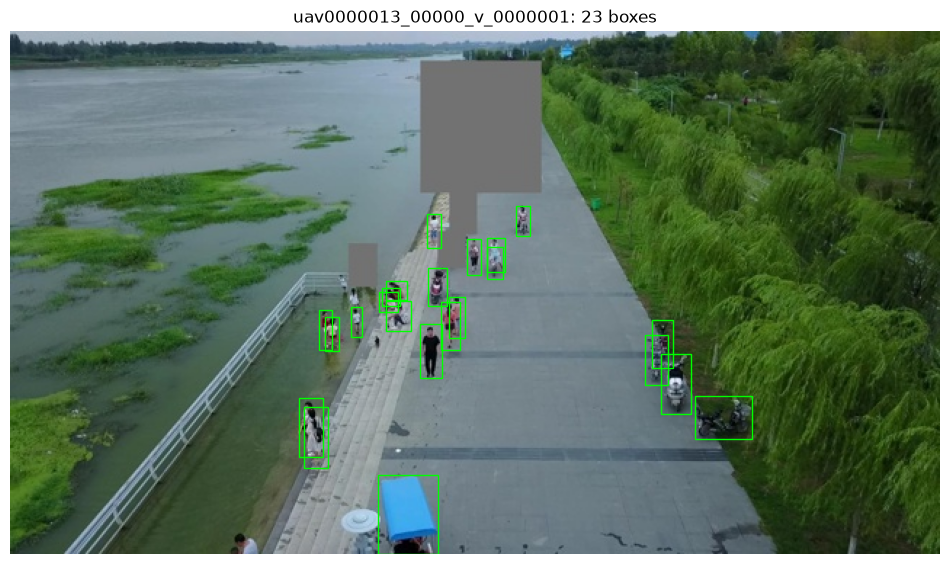

In [14]:
folder = f"{WORK}/fast/train"
name = sorted(os.listdir(f"{folder}/images"))[0][:-4]
image = Image.open(f"{folder}/images/{name}.jpg")
labels = np.loadtxt(f"{folder}/labels/{name}.txt", ndmin=2)
width, height = image.size

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)
for cls, cx, cy, w, h in labels:
    x = (cx - w / 2) * width
    y = (cy - h / 2) * height
    ax.add_patch(patches.Rectangle((x, y), w * width, h * height, fill=False, edgecolor="lime"))
ax.set_title(f"{name}: {len(labels)} boxes")
ax.axis("off")
plt.savefig(f"{IMAGES}/02_label_check.png", dpi=110)
plt.show()

## Conclusions
* **Label check.** The prepared image has 23 boxes and every box sits on an object. So the conversion from COCO to YOLO format is correct.
* **Ignored regions** are gray and have no boxes inside.
* **Validation:** 146 frames (every 20th frame of each val clip), the same for all models.
* **Step size.** Frames next to each other are almost the same. Every 100th frame keeps all clips but makes training fast. The final model uses every 20th frame.
* **Resizing.** One time before training: long side 640 px (fast) or 1024 px (final), same width / height ratio.
* **Normalization** is done inside torchvision and Ultralytics (pixels 0-255 → 0-1).
* **Augmentation** is done during training: left-right flip for torchvision, Ultralytics defaults (flip, mosaic, scale, colour) for YOLO and RT-DETR.